# CsI(Tl)–SiPM：Co 尾部、平均时间与 PID 的联合检查

2026-10-29。先以英文提交并推送 `455da70`，保存[run12噪声状态研究](codex_0001_csi_run12_noise_state.ipynb)，再进行本轮。
承接[下一步诊断](codex_0001_csi_next_steps_review.ipynb)：Co 的平均时间偏差主要表现为2–3 µs尾部贡献不足，旧形状目标没有直接约束这一量。

本轮只用 run3/run12 前60%实验波形联合拟合，保留四组目标/边界对照。冻结候选后完成 **8000 Co、24000 Am 新种子完整 Geant4 母衰变**，逐事件核查来源、能量和电荷守恒，再评估实际 ADC。

**Co尾部与平均时间改善，但还不能替换默认配置。** Co 后段平均时间差从约−16.2 ns变为+6.3 ns，仍有显著条件残差；Am平均时间带宽比的点估计却从0.82降至0.70。
平均波形、中心、宽度和参数可辨识性必须一起看，本轮完整保留这些取舍。


In [1]:
from pathlib import Path
import json, sys
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/co_tail_20261029'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def nums(x):return ' / '.join(f'{v:.3f}' for v in x)
def ci(a,kind,j,block='64'):
    lo,hi=a['uncertainty_by_data_block'][block][kind][j]['estimate95']
    return f'[{lo:.3f}, {hi:.3f}]'
r=read(OUT/'assessment.json');fit=read(OUT/'selection.json');design=read(OUT/'design.json');protocol=read(OUT/'native_protocol.json')
print('Python / NumPy:',sys.version.split()[0],np.__version__)
print('新增独立母事件:',r['new_independent_mothers'])
rows=[]
for key,e in protocol['entries'].items():
    a=read(OUT/'extraction'/f'{key}.json');v=read(OUT/'native'/f'{key}_validation.json')
    rows.append([key,e['events'],e['seed'],a['n_common'],a['common_truth_counts'],v['passed']])
display(Markdown(table(['场景','母衰变数','新种子','共同Q条数','祖先标签α/γ/衰变电子/混合/其他','原生检查'],rows)))

Python / NumPy: 3.13.5 2.5.4
新增独立母事件: 32000


|场景|母衰变数|新种子|共同Q条数|祖先标签α/γ/衰变电子/混合/其他|原生检查|
|---|---|---|---|---|---|
|run3_Co60|8000|301029503|247|[0, 246, 1, 0, 0]|True|
|run12_Am241|24000|301029512|194|[194, 0, 0, 0, 0]|True|

## 1. 目标函数与对照如何冻结

实验保持原冻结事件ID、主带诊断和Q分箱：run3使用6个支持箱，run12使用前3个，箱间等权。
每条波形用自己的前128点基线和正式整数积分锚点，先得到 `ADC/(2 Qlong)` 密度，再在箱内、箱间平均。
因此该平均密度的一阶矩，严格等于等权箱内逐事件正式平均时间的均值；不是把中位数带中心替换成均值。
原始 ADC 图另按分数 t₁₀ 对齐，两种定义明确分开。

四组都拟合电子/α两分量时间与份额、共同RC；保持SPE 2/29 ns、PDE=0.3、共同被动电压传输0.5、几何、电子噪声和信号期残差固定。

- `legacy_objective`：沿用早期0–600 ns额外4倍形状权重和5个旧描述量，不加尾部惩罚；电子慢分量下界700 ns。
- `tail_old_bound`：形状时间权重均匀，加入平均时间、2–3 µs电荷份额与该片一阶矩贡献，下界仍700 ns。
- **`tail_relaxed_bound`：预先指定的主候选**，同样的尾部目标，将电子慢分量下界放到400 ns。
- `tail_half_weight`：相对主候选，将尾部残差系数乘0.5，即平方目标中的对应权重乘0.25。

尾部三个残差的尺度分别为5 ns、0.002、5 ns。它们相互相关，这些尺度是描述性目标权重，**不是独立测量误差，也不是卡方似然**。
每组预设3个起点，选该组中收敛且目标最小的结果；没有用后段实验波形挑选主候选。
原目标与新目标同时改变了早期权重和尾部约束，不能把效果单独归因于其中某一项。

快速卷积只提出参数。用旧原生MC与卷积的固定平滑差来校正提议误差，**该差不写入原生波形**。
旧MC从此是校准支撑，不再把它与新候选的比较称为独立的成对验证。原生输出只来自真实Geant4输运、SiPM雪崩和C++数字化。


主候选在完整输运前已冻结: tail_relaxed_bound


|提议组|电子τ/ns|ατ/ns|共同RC/ns|Co平均时间差/ns|Am平均时间差/ns|Co形状NRMSE|Am形状NRMSE|
|---|---|---|---|---|---|---|---|
|legacy_objective|92.708 / 700.000|888.441 / 15000.000|113.32|-11.357|-1.710|0.994%|0.649%|
|tail_old_bound|136.373 / 779.517|856.442 / 15000.000|115.15|+5.205|+0.864|1.367%|0.609%|
|tail_relaxed_bound|136.373 / 779.517|856.442 / 15000.000|115.15|+5.205|+0.864|1.367%|0.609%|
|tail_half_weight|127.944 / 767.800|860.645 / 15000.000|115.03|+4.832|+1.038|1.291%|0.612%|

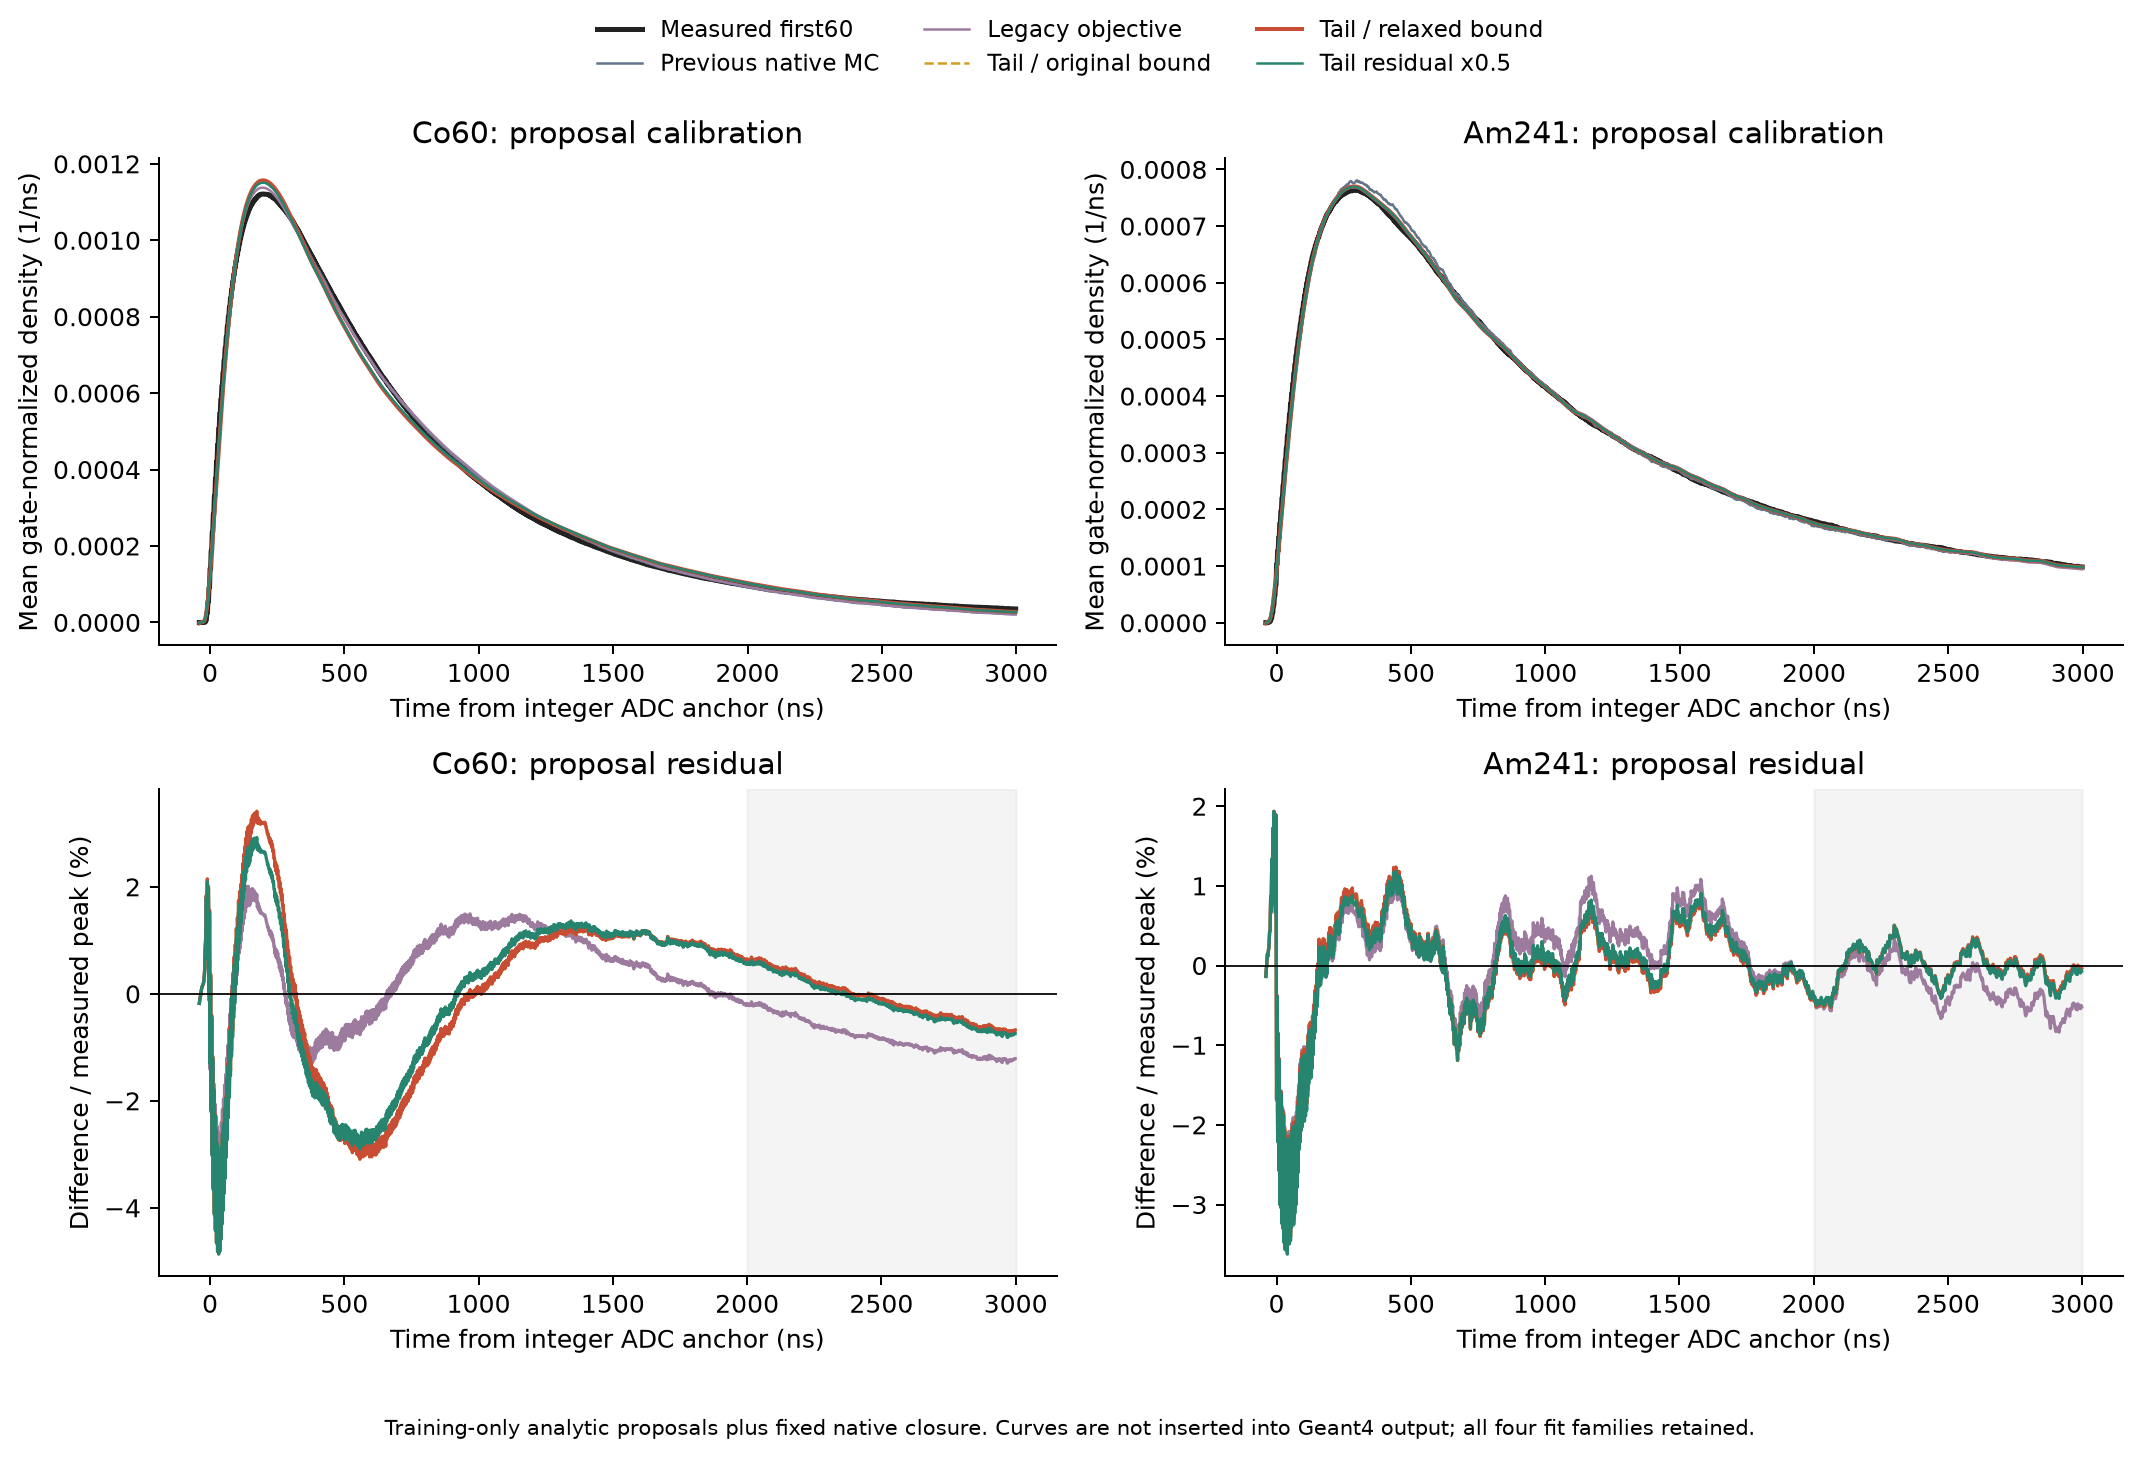

In [2]:
rows=[]
for name,f in fit['cases'].items():
    b=f['best'];p=b['parameters']
    rows.append([name,nums(p['electron_tau_ns']),nums(p['alpha_tau_ns']),f"{p['lowpass_ns']:.2f}",
        f"{b['metrics']['Co60']['tail_difference'][0]:+.3f}",f"{b['metrics']['Am241']['tail_difference'][0]:+.3f}",
        f"{100*b['metrics']['Co60']['shape_NRMSE']:.3f}%",f"{100*b['metrics']['Am241']['shape_NRMSE']:.3f}%"])
display(Markdown(table(['提议组','电子τ/ns','ατ/ns','共同RC/ns','Co平均时间差/ns','Am平均时间差/ns','Co形状NRMSE','Am形状NRMSE'],rows)))
display(Image(filename=str(OUT/'figures/tail_training_families.png')))
print('主候选在完整输运前已冻结:',fit['selected_case'])

## 2. 边界与归一化：尚未测出唯一的物理参数

带尾部约束时，原700 ns下界与放宽400 ns下界得到的电子时间几乎相同，慢分量约780 ns。
本组结果不支持“只是旧700 ns硬下界造成偏差”这一解释；目标函数组合的变化更关键。

但所有本轮最优α慢分量都触及15 µs上界，而拟合积分门只有3 µs、原记录总长约5 µs。
有限窗口内可以用慢分量份额、衰减时间与总产额互相补偿，**15 µs不能当作已经测量的材料常数**。

本轮使用一个共同光产额乘子保持解析电子3 µs积分，再调整α相对归一化保持对应α积分；这是全局参数变更，没有逐条缩放实测/模拟幅度。
这一过程把有效α归一化推到1以上，是模型退化与条件假设的提示，不能写成实测“α淬灭因子大于1”。
已知读出求和细节、源距等仍不完整；默认配置保持原样。


In [3]:
c=read(OUT/'configs/run12_Am241.json')
display(Markdown(table(['项目','本轮数值'],[
    ['电子解析积分补偿倍数',fit['analytic_gate_area_multipliers']['electron']],
    ['α解析积分补偿倍数',fit['analytic_gate_area_multipliers']['alpha']],
    ['共同有效光产额/ph per MeV',c['optical']['yield_photons_per_MeV']],
    ['有效α相对归一化',c['optical']['alpha_light_yield_ratio']],
    ['α慢分量/ns',fit['chosen_parameters']['alpha_tau_ns'][1]]])))
print('所有旧配置证据字段仅为继承历史；本轮数值/范围以tail_refit、design和selection为准。')

所有旧配置证据字段仅为继承历史；本轮数值/范围以tail_refit、design和selection为准。


|项目|本轮数值|
|---|---|
|电子解析积分补偿倍数|1.0064706623899184|
|α解析积分补偿倍数|1.2399498599848062|
|共同有效光产额/ph per MeV|35408.03174483674|
|有效α相对归一化|1.1974163262907365|
|α慢分量/ns|14999.999999999976|

## 3. 完整 Geant4：中心与尾部得到多大改善

下面使用真实 ADC 重新执行正式质量/Q选择，模拟不加PID分数切割。新种子的母衰变分别为8000/24000；共同Q内事件数远少于母事件数。
Co新样本中有1条沉积祖先以衰变电子为主的事件，仍按原无PID切割规则保留；²⁴¹Am包含α、γ和衰变电子，源名不是实验逐事件真值。

区间为512次整母事件重采样与实验原始序号块64/128重采样。新旧输运历史不同，各自采样；没有把它们配成同一母事件。
拟合、闭合修正、噪声和装置参数都固定，区间未包含这部分不确定性，也未作多重比较校正。
前60%属于训练检查；中/后段是此前已经探索过的内部检验，不能叫新实验盲验证。


|组|模型|MC数|平均时间差/ns|95%区间|尾部电荷差/百分点|尾部一阶矩差/ns|
|---|---|---|---|---|---|---|
|run3_first60|old|280|-15.874|[-17.836, -13.842]|-0.956|-24.851|
|run3_first60|new|247|+6.648|[4.749, 8.762]|-0.083|-3.205|
|run3_middle20|old|280|-17.141|[-19.128, -15.075]|-0.990|-25.730|
|run3_middle20|new|247|+5.381|[3.253, 7.760]|-0.118|-4.084|
|run3_last20|old|280|-16.206|[-18.426, -14.263]|-0.957|-24.621|
|run3_last20|new|247|+6.316|[3.907, 9.006]|-0.084|-2.975|
|run12_first60|old|206|-7.040|[-12.009, -2.328]|-0.278|-6.760|
|run12_first60|new|194|-2.981|[-8.024, 1.427]|-0.156|-4.135|
|run12_middle20|old|206|-7.417|[-13.403, -1.918]|-0.349|-8.673|
|run12_middle20|new|194|-3.358|[-10.044, 2.401]|-0.227|-6.048|
|run12_last20|old|206|-1.978|[-8.318, 4.248]|-0.089|-1.570|
|run12_last20|new|194|+2.080|[-3.622, 7.725]|+0.034|+1.054|

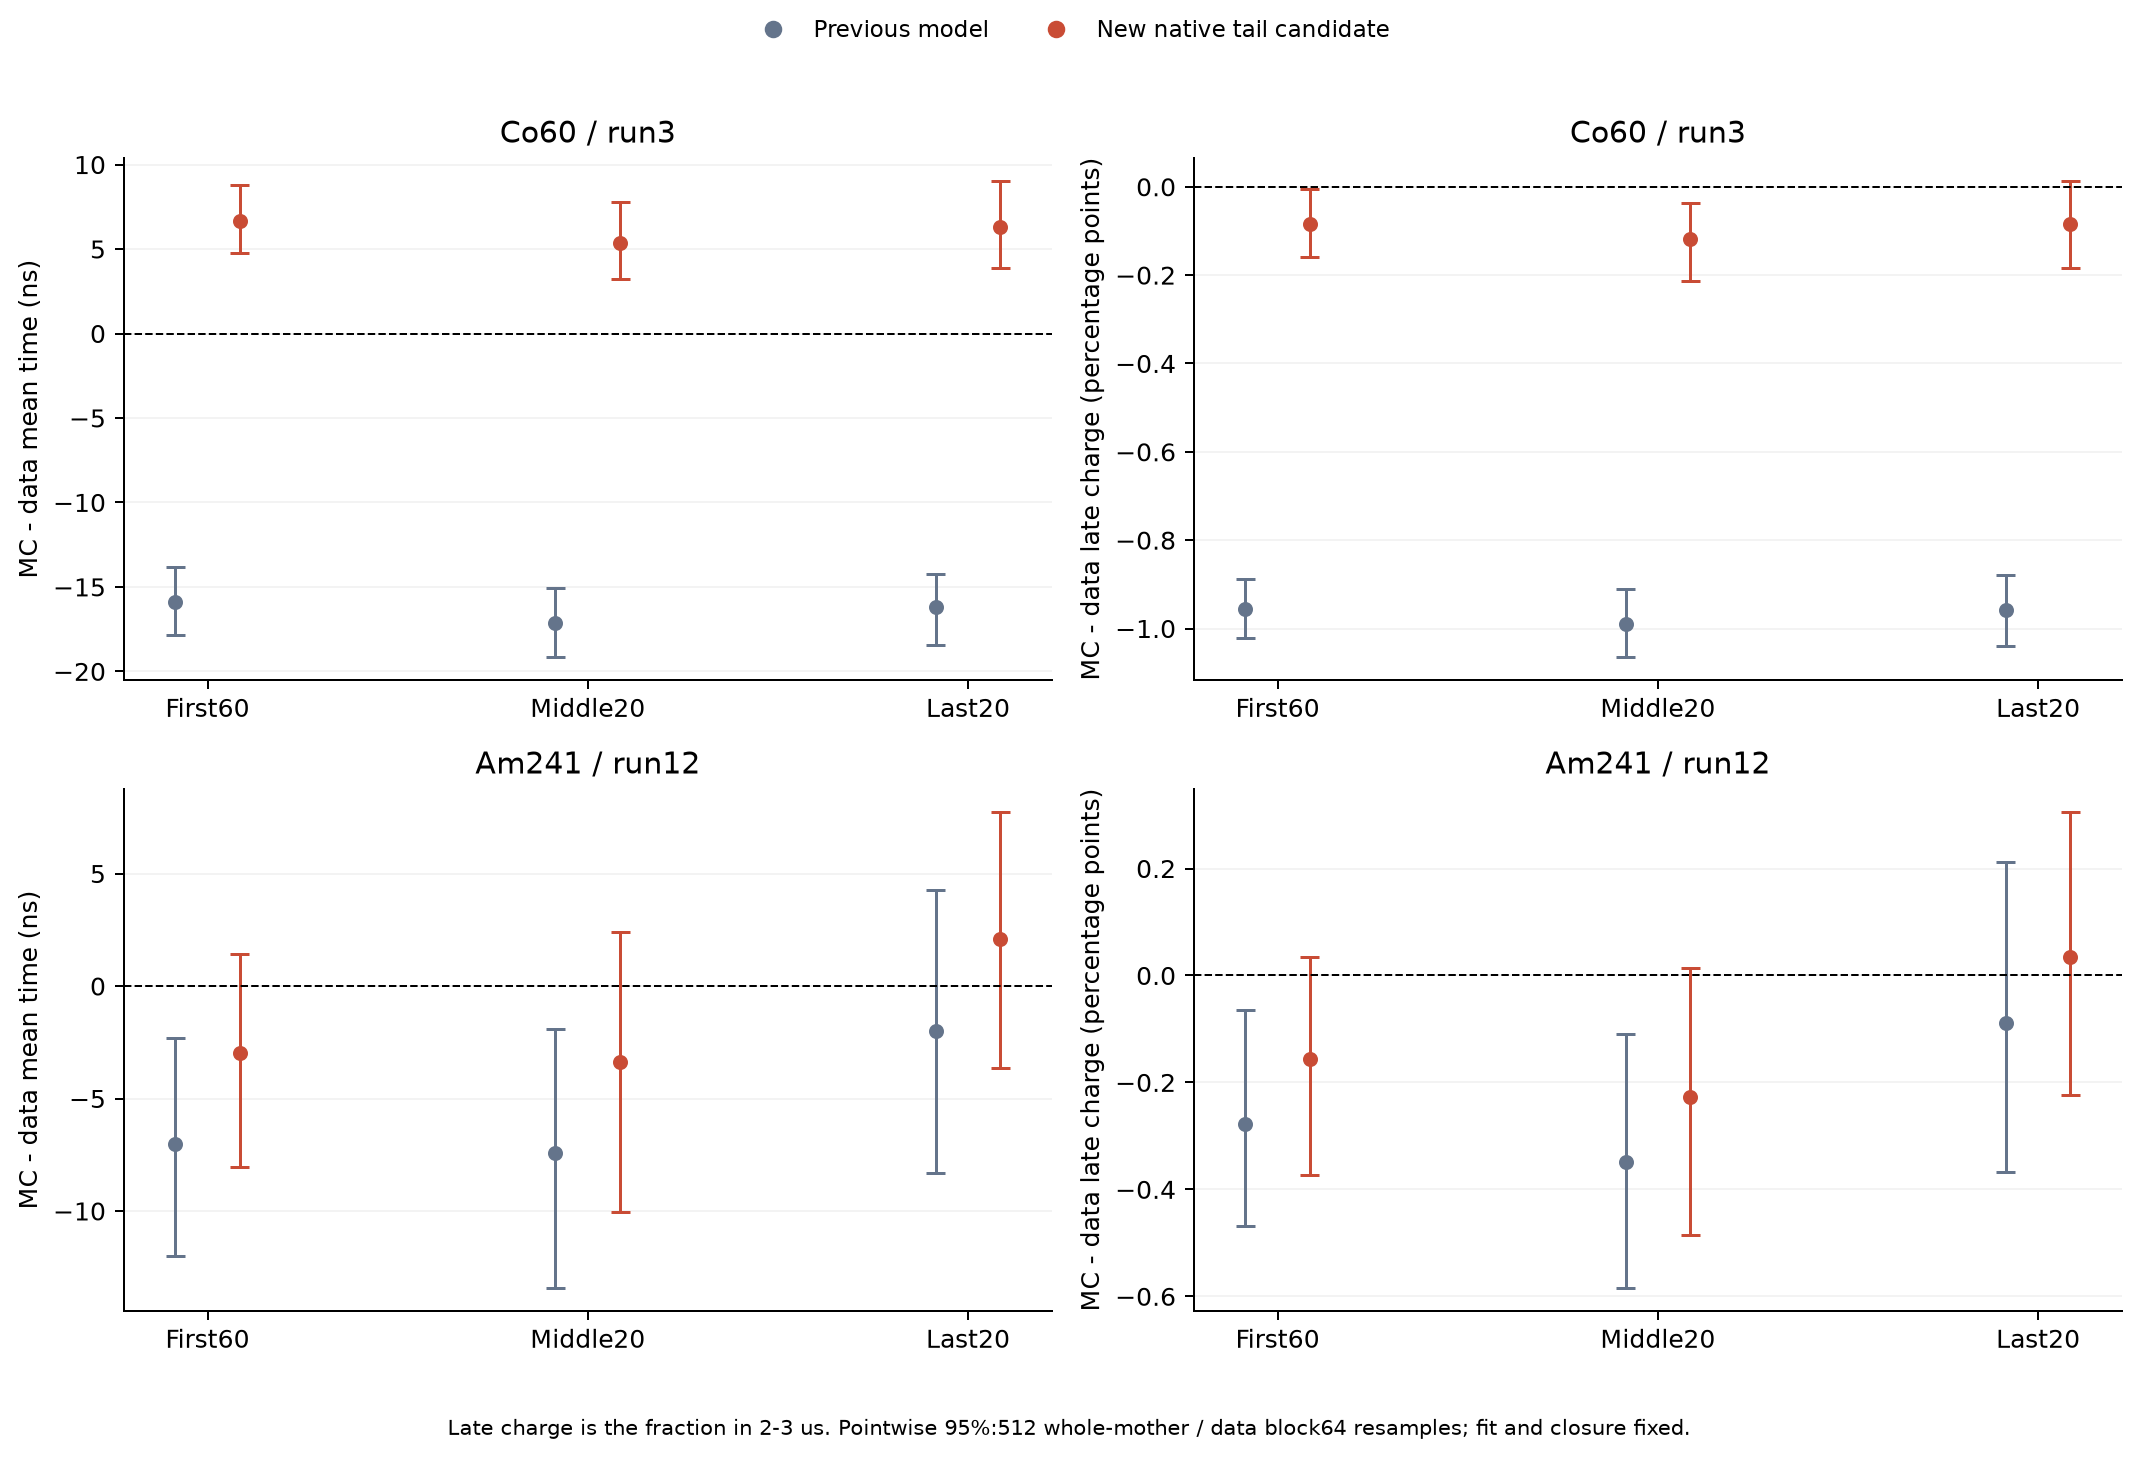

|新候选后段|块64平均时间差区间/ns|块128区间/ns|
|---|---|---|
|run3_last20|[3.907, 9.006]|[4.122, 8.725]|
|run12_last20|[-3.622, 7.725]|[-5.214, 8.812]|

In [4]:
rows=[]
for group,a in r['checks'].items():
    for name,m in a['models'].items():
        rows.append([group,name,m['n_MC'],f"{m['tail_difference'][0]:+.3f}",ci(m,'tail_difference_CI95',0),
            f"{100*m['tail_difference'][1]:+.3f}",f"{m['tail_difference'][2]:+.3f}"])
display(Markdown(table(['组','模型','MC数','平均时间差/ns','95%区间','尾部电荷差/百分点','尾部一阶矩差/ns'],rows)))
display(Image(filename=str(OUT/'figures/tail_native_moments.png')))
rows=[]
for group in ['run3_last20','run12_last20']:
    m=r['checks'][group]['models']['new']
    rows.append([group,ci(m,'tail_difference_CI95',0,'64'),ci(m,'tail_difference_CI95',0,'128')])
display(Markdown(table(['新候选后段','块64平均时间差区间/ns','块128区间/ns'],rows)))

## 4. 平均 ADC 波形：不能只看某一指标

原始 ADC 均值先扣本事件基线、按t₁₀对齐，再在原Q支持箱等权平均；没有重新缩放模拟峰值。
NRMSE是−40至3000 ns均方根差除以实测均波形峰值。
新Co尾部更接近，但整段均波形NRMSE上升；Am均波形NRMSE下降。两源同时报告，避免只展示改善的局部。


|组|模型|均ADC NRMSE/峰|均ADC峰比|F50/F102/F202比|
|---|---|---|---|---|
|run3_first60|old|0.961%|1.0248|1.019 / 1.033 / 1.005|
|run3_first60|new|1.453%|1.0309|0.983 / 1.015 / 1.025|
|run3_middle20|old|0.983%|1.0264|1.030 / 1.055 / 1.036|
|run3_middle20|new|1.438%|1.0325|0.994 / 1.037 / 1.057|
|run3_last20|old|0.957%|1.0262|1.059 / 1.072 / 1.042|
|run3_last20|new|1.429%|1.0323|1.021 / 1.053 / 1.063|
|run12_first60|old|1.129%|1.0250|1.030 / 1.017 / 1.026|
|run12_first60|new|0.793%|1.0151|1.000 / 1.003 / 1.032|
|run12_middle20|old|1.120%|1.0173|1.052 / 1.037 / 1.038|
|run12_middle20|new|0.848%|1.0075|1.022 / 1.023 / 1.044|
|run12_last20|old|1.169%|1.0134|1.065 / 1.037 / 1.042|
|run12_last20|new|0.633%|1.0036|1.034 / 1.023 / 1.048|

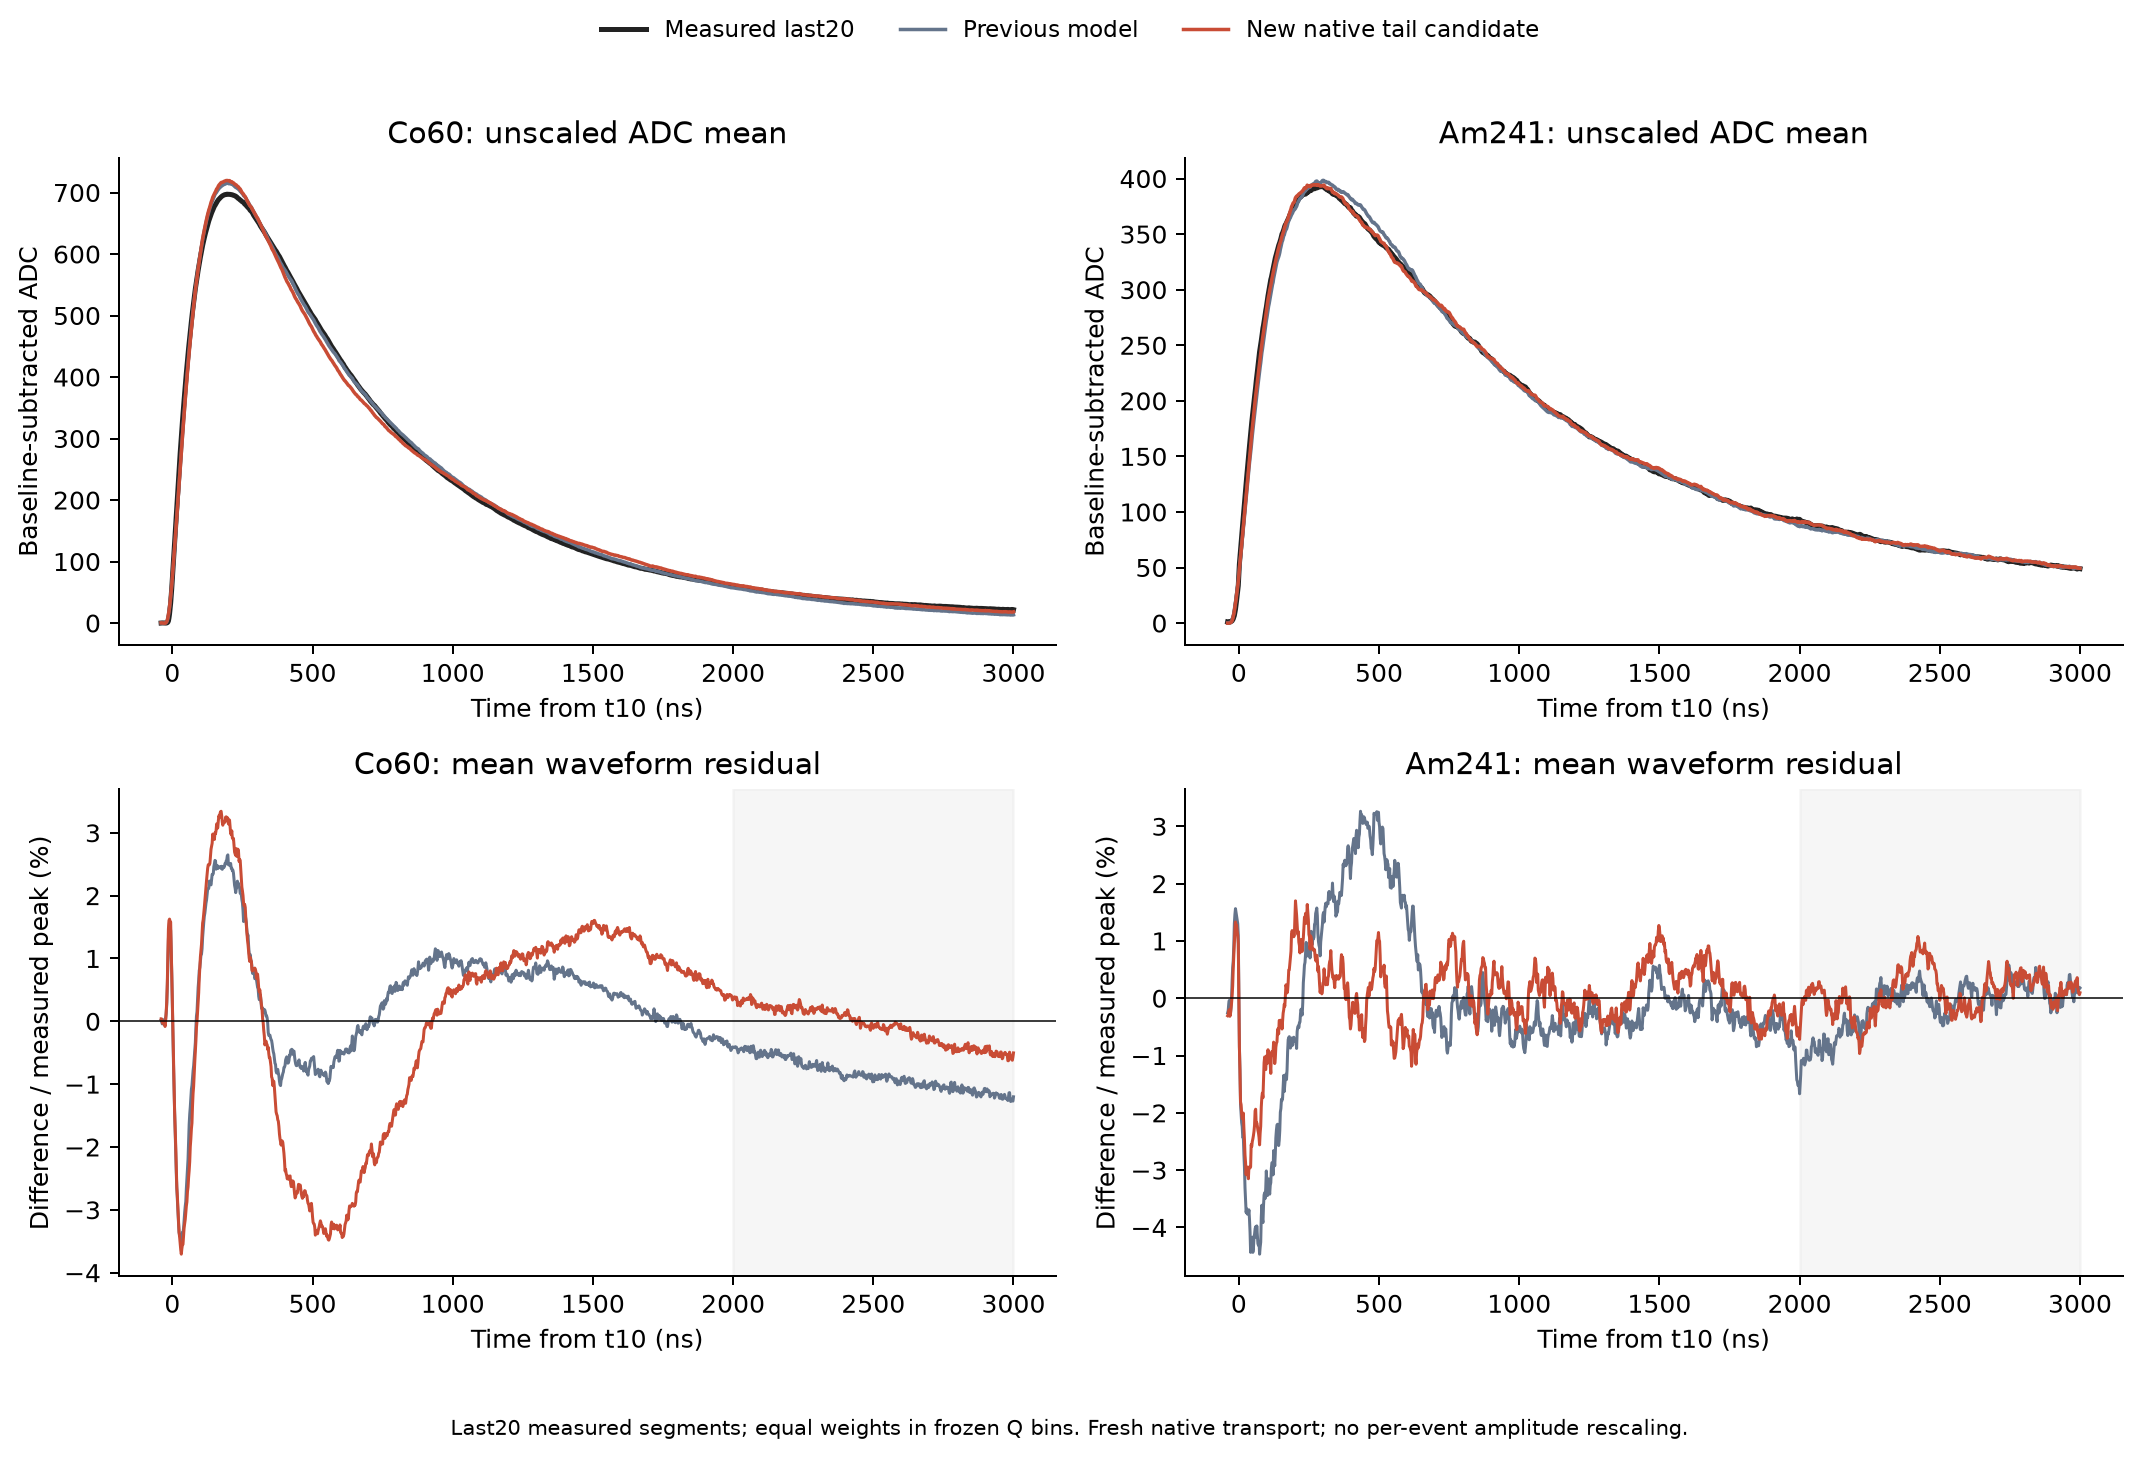

In [5]:
rows=[]
for group,a in r['checks'].items():
    for name,m in a['models'].items():
        rows.append([group,name,f"{100*m['mean_ADC_normalized_RMSE']:.3f}%",f"{m['mean_ADC_peak_ratio']:.4f}",nums(m['F_ratio'])])
display(Markdown(table(['组','模型','均ADC NRMSE/峰','均ADC峰比','F50/F102/F202比'],rows)))
display(Image(filename=str(OUT/'figures/tail_native_waveforms.png')))

## 5. PID 宽度仍是必须保护的约束

带宽沿用每个Q箱IQR再等权取RMS，分母为对应实验主带诊断。实验主带分界不代表纯粒子样本。
Co三个后段宽度比点估计约0.95/0.94/0.94；Am QDC/PCA接近1，但平均时间宽度比点估计约0.70，其固定模型点态95%区间仍未覆盖1。
不同原生种子的区间有重叠，不能把所有新旧点估计变化都当成已经统计证明的因果改善/退化。

Co后段平均时间均值差仍约+6 ns，条件区间未覆盖0，说明中心并未完全一致。
这一轮也没有把两源置于同一采集噪声状态来重算ROC，所以**不更新模拟α接受率/γ泄漏率，更不推断实验效率**。


|组|模型|QDC/平均时间/PCA宽度比|平均时间宽度比95%区间|三个中位数中心差/实验IQR|
|---|---|---|---|---|
|run3_first60|old|1.063 / 0.948 / 1.041|[0.775, 1.089]|0.213 / 0.750 / 0.300|
|run3_first60|new|0.862 / 0.930 / 0.948|[0.769, 1.075]|-0.030 / -0.383 / -0.113|
|run3_middle20|old|1.148 / 1.121 / 1.171|[0.834, 1.320]|0.323 / 1.044 / 0.406|
|run3_middle20|new|0.931 / 1.100 / 1.067|[0.832, 1.327]|0.057 / -0.294 / -0.055|
|run3_last20|old|1.168 / 0.954 / 1.036|[0.779, 1.159]|0.236 / 0.786 / 0.299|
|run3_last20|new|0.948 / 0.936 / 0.943|[0.768, 1.164]|-0.034 / -0.394 / -0.118|
|run12_first60|old|0.956 / 0.964 / 0.942|[0.778, 1.155]|0.060 / 0.151 / 0.072|
|run12_first60|new|1.012 / 0.819 / 1.082|[0.683, 1.078]|0.056 / 0.122 / 0.089|
|run12_middle20|old|1.000 / 0.809 / 0.973|[0.649, 1.005]|-0.059 / 0.104 / 0.046|
|run12_middle20|new|1.058 / 0.687 / 1.117|[0.533, 0.964]|-0.070 / 0.061 / 0.056|
|run12_last20|old|0.897 / 0.822 / 0.858|[0.650, 0.985]|-0.075 / 0.062 / -0.003|
|run12_last20|new|0.949 / 0.698 / 0.985|[0.559, 0.948]|-0.066 / 0.049 / 0.029|

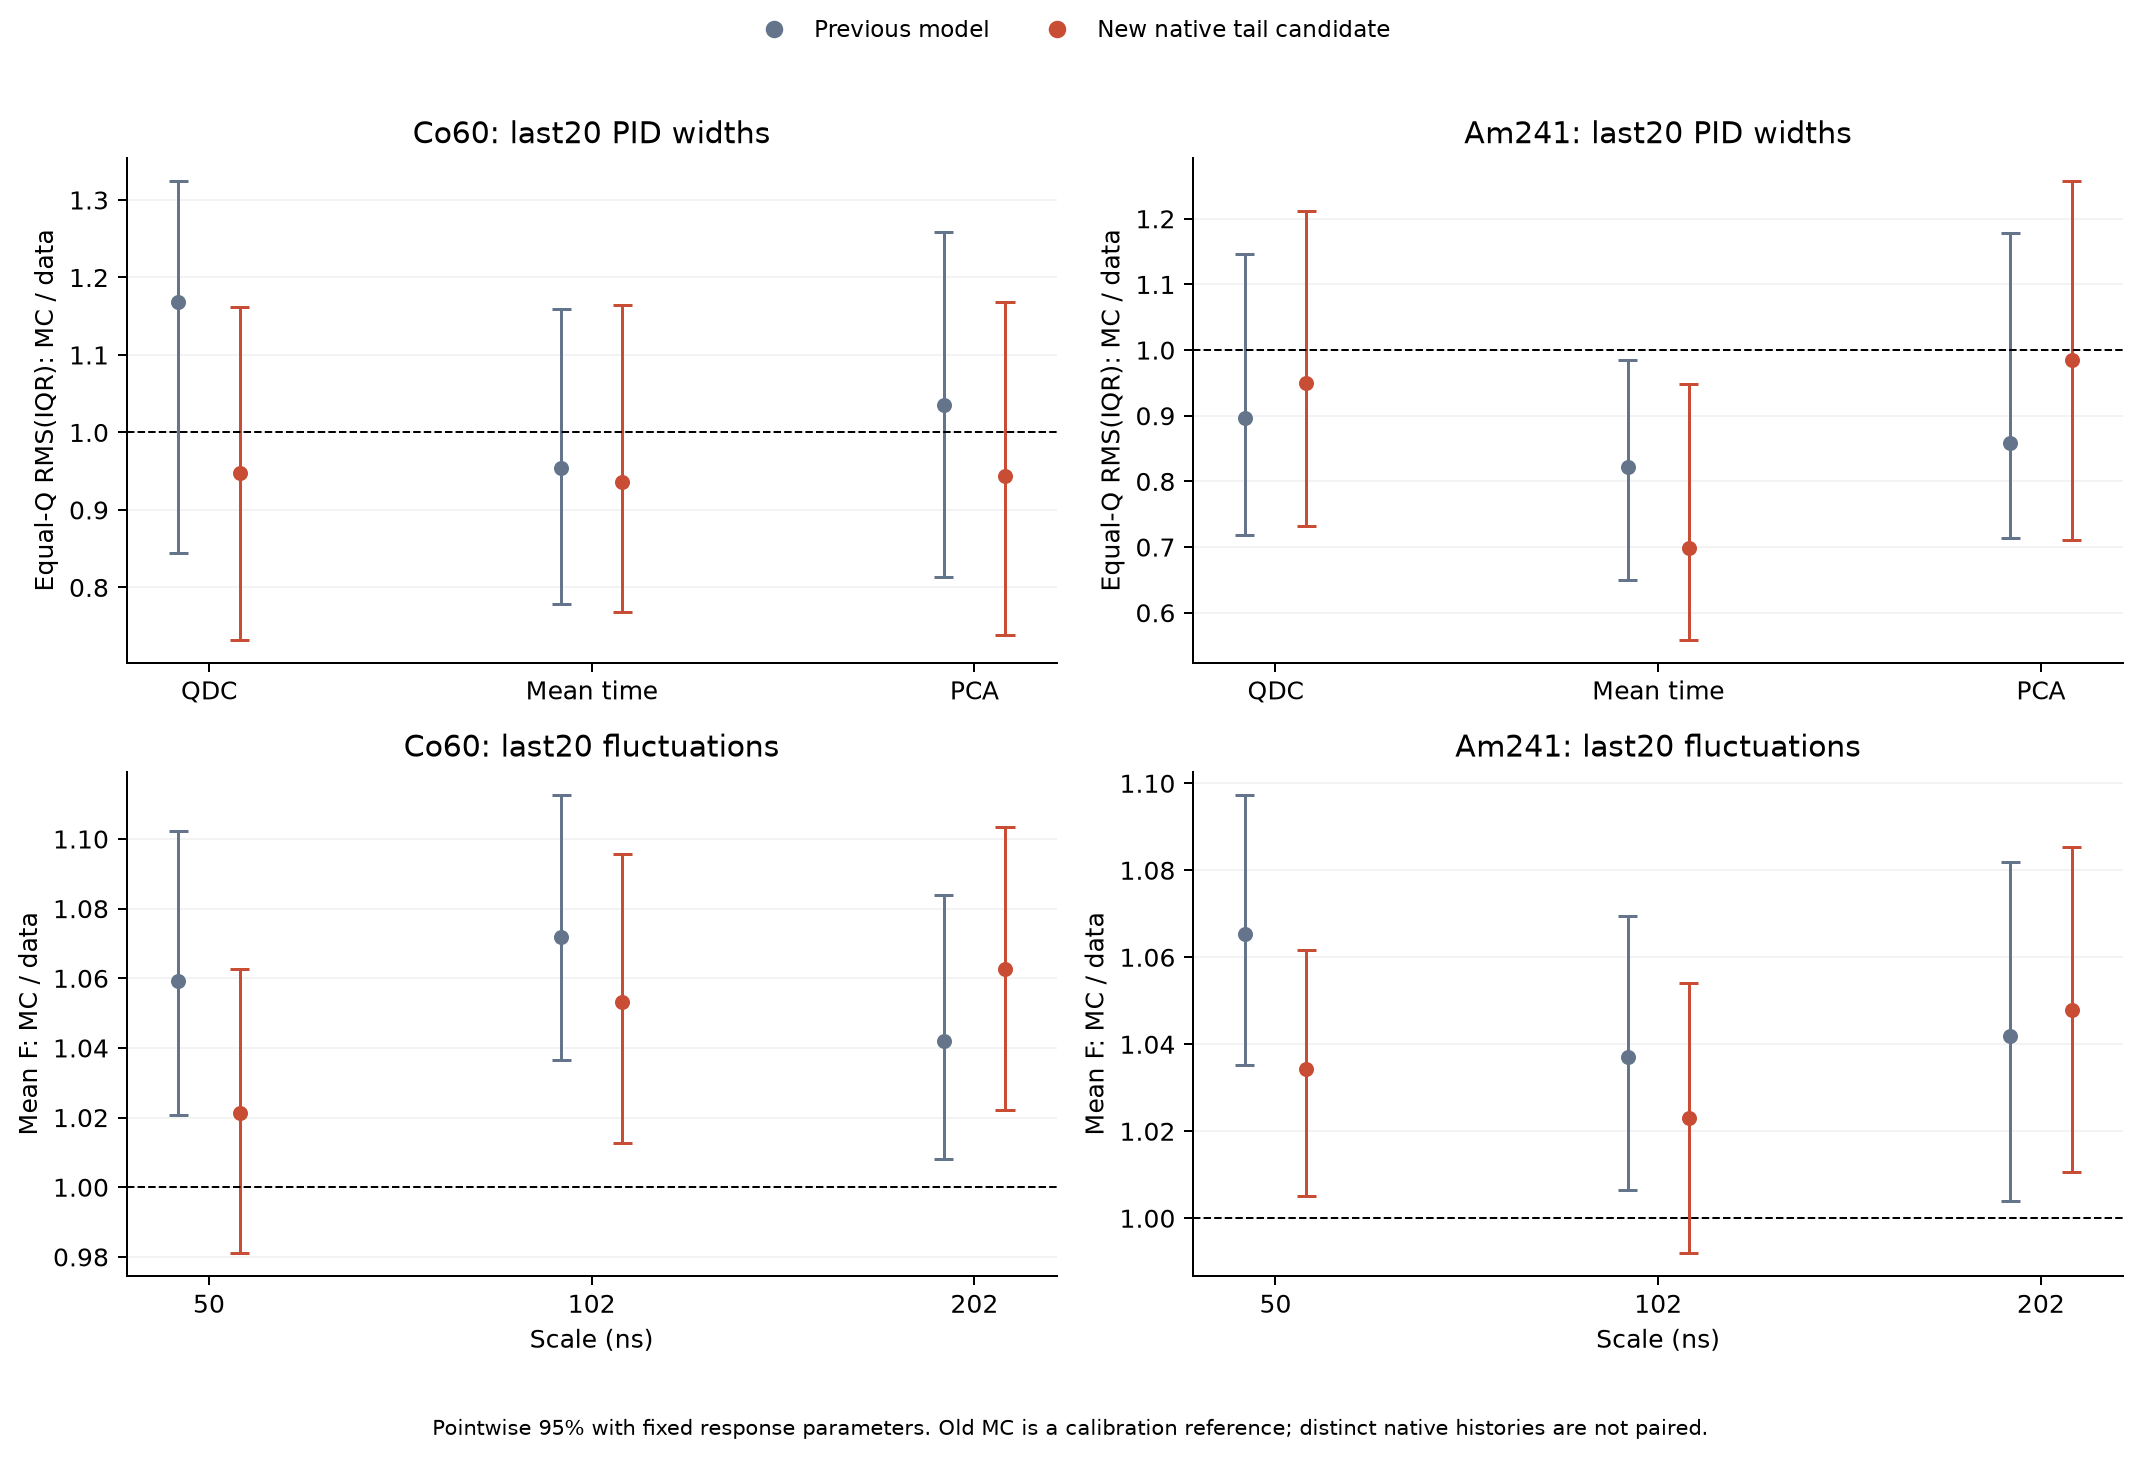

In [6]:
rows=[]
for group,a in r['checks'].items():
    for name,m in a['models'].items():
        rows.append([group,name,nums(m['IQR_ratio']),ci(m,'IQR_ratio_CI95',1),nums(m['median_shift_in_data_IQR'])])
display(Markdown(table(['组','模型','QDC/平均时间/PCA宽度比','平均时间宽度比95%区间','三个中位数中心差/实验IQR'],rows)))
display(Image(filename=str(OUT/'figures/tail_native_pid_controls.png')))

## 6. 精确的时间片贡献分解

按原积分门，每条波形将一阶矩拆到−40/0/200/500/1000/1500/2000/3000 ns时间片，再以原支持Q箱等权平均。
每一片共用该事件自己的完整Qlong分母，各片之和严格等于正式平均时间均值。
新模型减少了Co的2–3 µs负差，同时其他片出现正差，总差转为正值；这不是某一种机制的因果百分比分解。
图为分片点估计，总差的条件区间见前节。


12组时间片和与正式平均时间差一致。


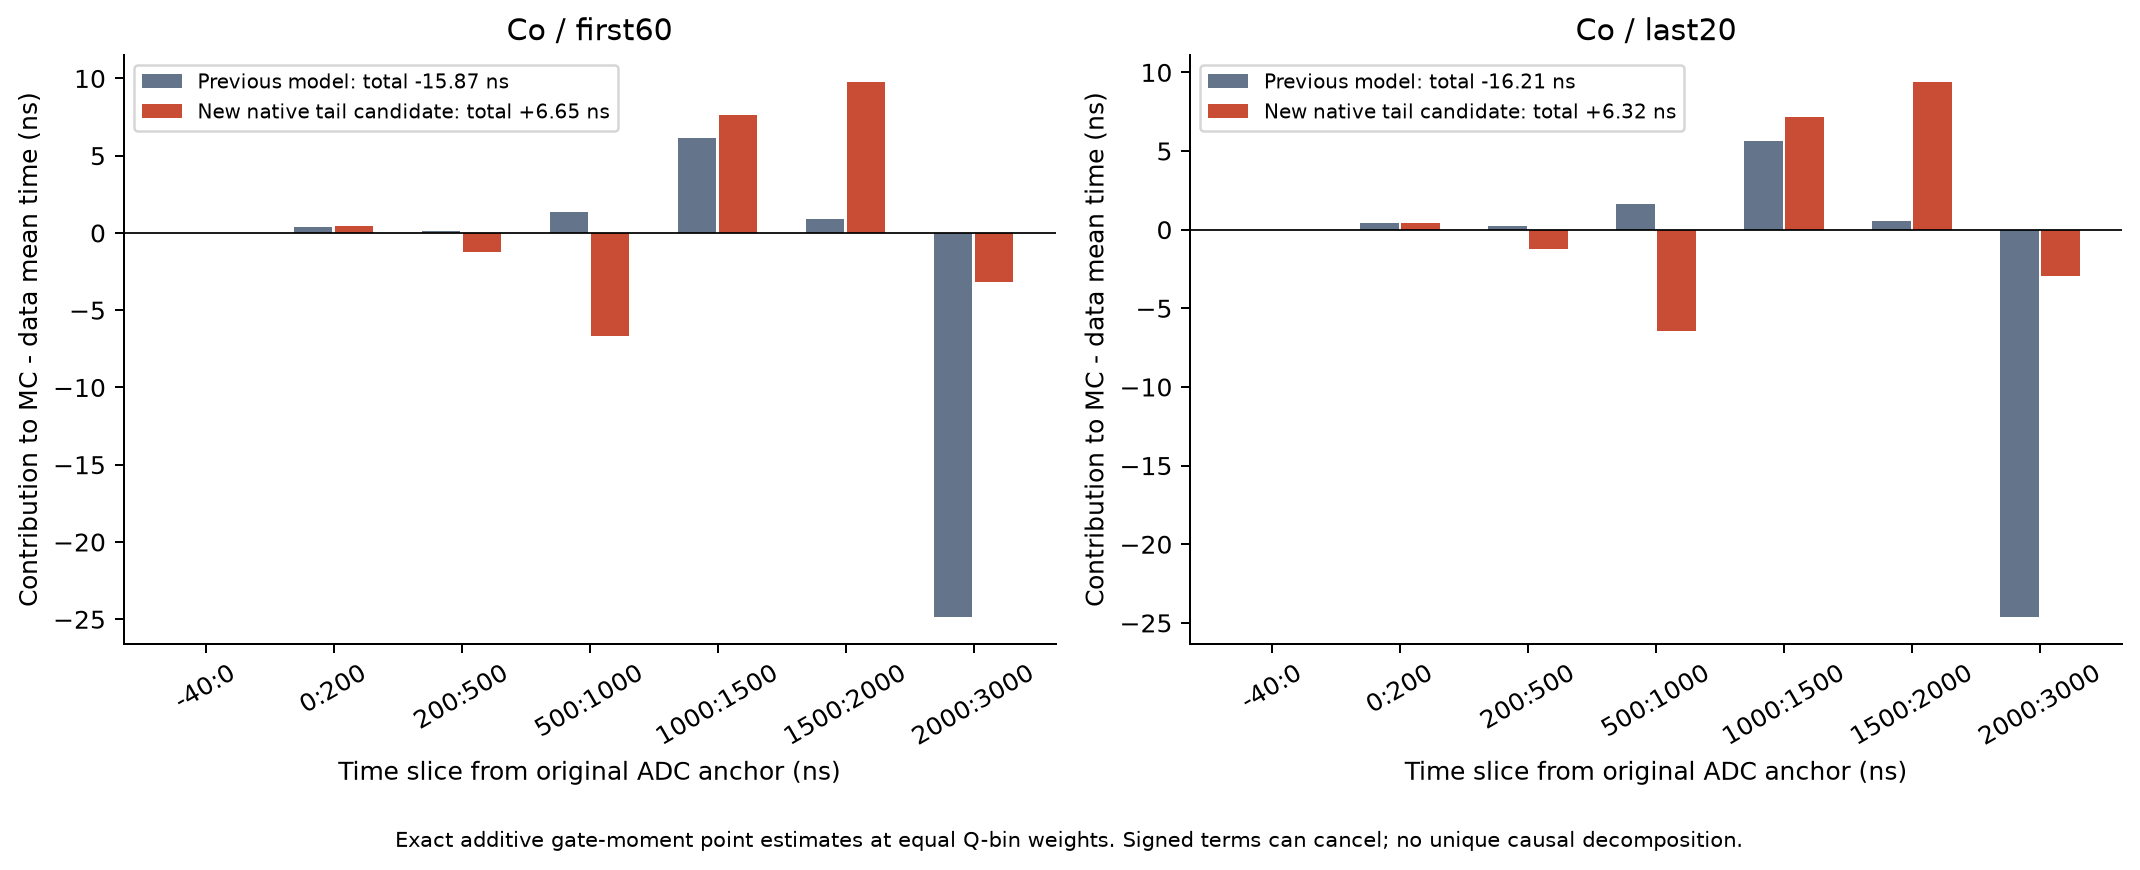

In [7]:
display(Image(filename=str(OUT/'figures/tail_time_contributions.png')))
for group in r['checks']:
    for name,m in r['checks'][group]['models'].items():
        assert abs(sum(m['mean_time_slice_difference_ns'])-m['tail_difference'][0])<1e-8
print('12组时间片和与正式平均时间差一致。')

## 7. 决策与下一阶段

保留这组候选作为**尾部目标函数敏感性实验**，不覆盖默认模型。它验证了目标函数需要显式约束尾部/平均时间，但还没有同时达到完整分布一致。

下一轮应在前60%中同时约束平均时间中心、三种PID协方差/宽度、均ADC及短尺度F，保留受约束的α长分量/归一化参数族。
可先比较固定旧α慢分量与合理范围内的剖面，检查是否能够避免边界和归一化补偿；信号期相关残差也应随新光学/RC重新校准，而不是只调大基线噪声。
只有在参数与规则再次冻结后，才用新种子检验；本轮后段结果不得回流到这一份冻结拟合。

此前run12前触发状态研究继续独立保留。本轮用了原前段噪声配置，没有把噪声条件化和时间参数一起改动；run18也未在这轮重新验证。


In [8]:
d=read(OUT/'decision.json');display(Markdown(d['conclusion_zh']))
print('默认配置已替换:',d['promoted_to_default'])
print('复现：fit_co_tail.py → run_co_tail.py → analyze_co_tail.py → plot_co_tail.py')
print('核查/归档：simulation/verify_co_tail.py；完成目录与notebook拒绝覆盖。')
print('数值表：',OUT/'validation_table.csv')
print('每阶段的配置、命令、种子、哈希与条件限制均保存在结果目录。')

默认配置已替换: False
复现：fit_co_tail.py → run_co_tail.py → analyze_co_tail.py → plot_co_tail.py
核查/归档：simulation/verify_co_tail.py；完成目录与notebook拒绝覆盖。
数值表： /media/sf_works/SiPM/simulation/results/co_tail_20261029/validation_table.csv
每阶段的配置、命令、种子、哈希与条件限制均保存在结果目录。


完整Geant4后段检查：Co平均时间差由 -16.21 ns 变为 +6.32 ns，2–3 µs电荷份额差由 -0.957 变为 -0.084 个百分点。新候选Co/Am均ADC波形NRMSE分别为 1.43% / 0.63%。Am平均时间宽度比点估计由 0.822 变为 0.698，仍偏窄。宽度、起伏和参数边界仍需一起评估；本轮不自动替换默认配置。